In [2]:
import pandas as pd

HOUSE PRICE PREDICTION - REGRESSION PROJECT

[STEP 1] Loading Dataset...
----------------------------------------------------------------------
✓ Dataset loaded successfully!
  Shape: (506, 14)
  Rows: 506 | Columns: 14

[STEP 2] Exploratory Data Analysis
----------------------------------------------------------------------

📊 First 5 rows:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  

📊 Dataset In

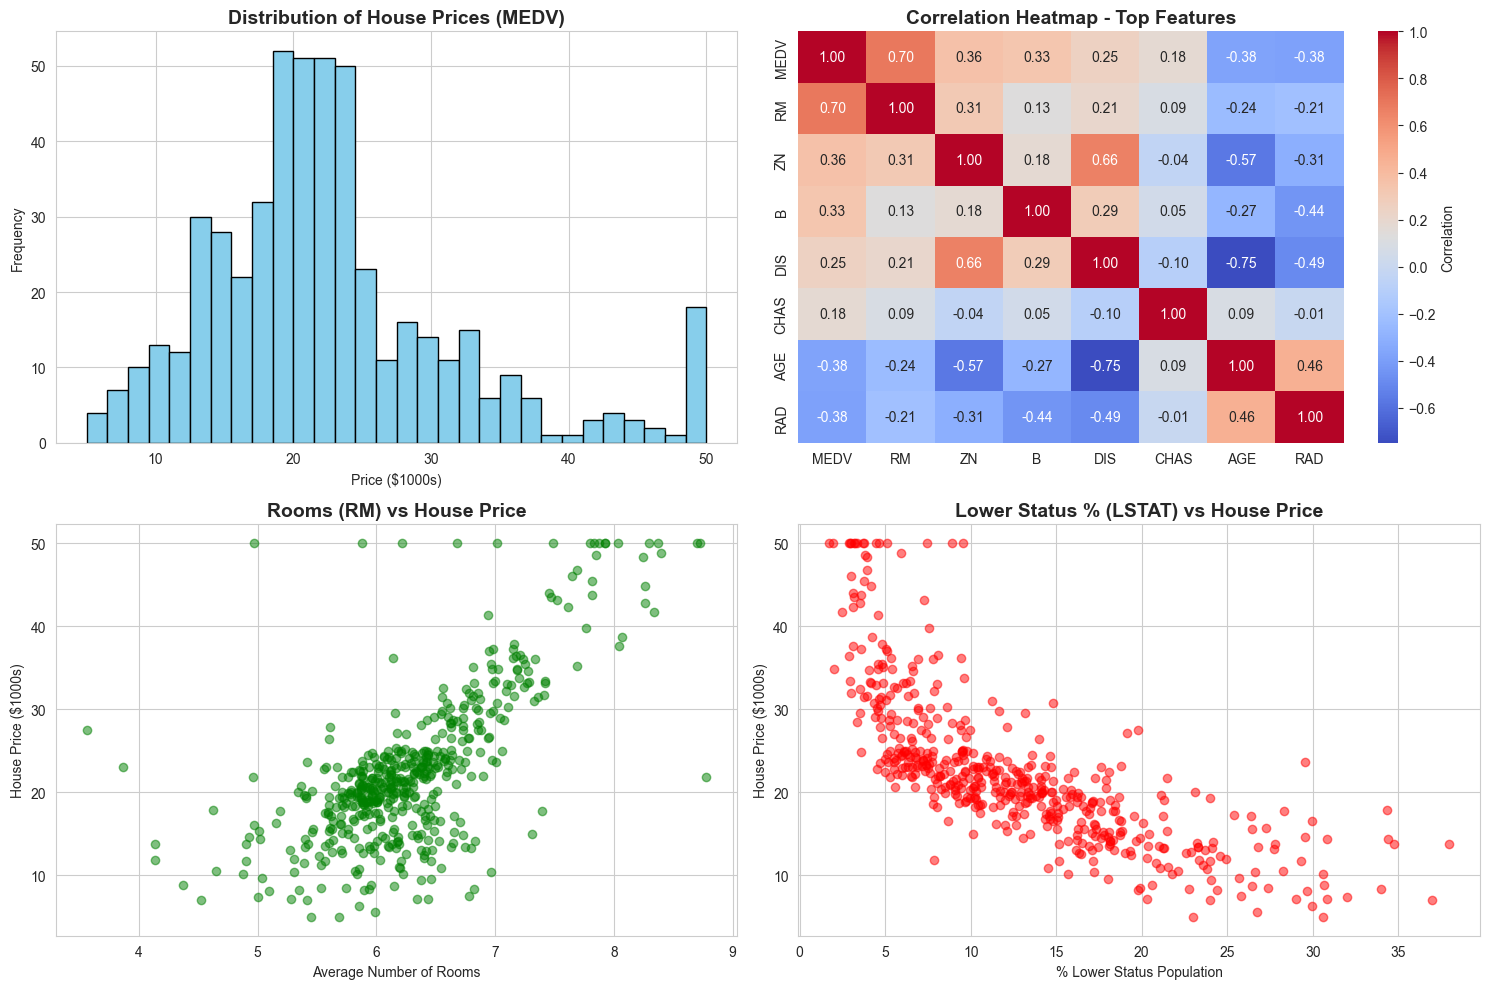


[STEP 4] Preparing Data for Modeling
----------------------------------------------------------------------
✓ Features (X): (506, 13)
✓ Target (y): (506,)

✓ Training set: 404 samples
✓ Testing set: 102 samples
✓ Split ratio: 80% train, 20% test

[STEP 5] Building and Training Models
----------------------------------------------------------------------

🔧 Training Linear Regression...
   ✓ Linear Regression trained successfully!

🔧 Training Decision Tree...
   ✓ Decision Tree trained successfully!

🔧 Training Random Forest...
   ✓ Random Forest trained successfully!

[STEP 6] Model Performance Evaluation

📊 MODEL COMPARISON TABLE:
----------------------------------------------------------------------
            Model  Train RMSE  Test RMSE  Train R²  Test R²  Test MAE
Linear Regression    4.652033   4.928602  0.750886 0.668759  3.189092
    Decision Tree    0.742791   4.746060  0.993649 0.692842  2.805952
    Random Forest    1.493789   2.785467  0.974314 0.894198  2.013292

🏆 BEST 

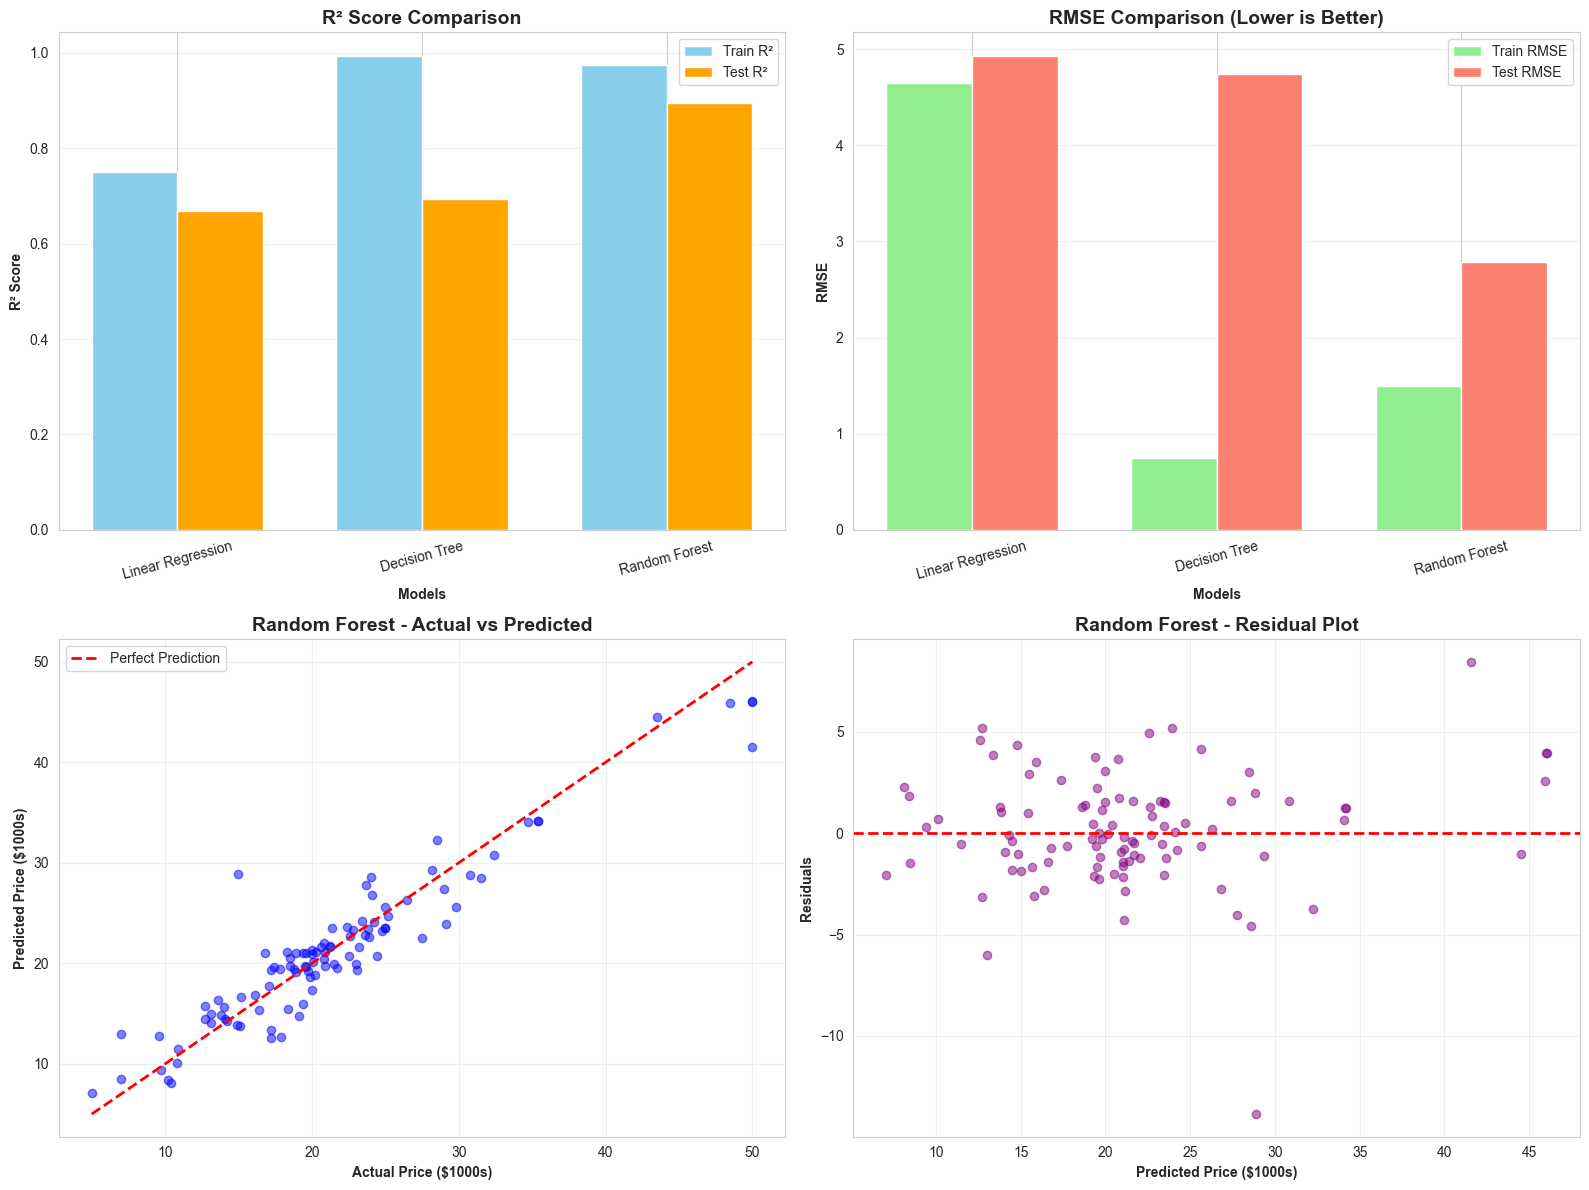


[STEP 8] Feature Importance Analysis
----------------------------------------------------------------------

📊 Top 10 Important Features (Random Forest):
Feature  Importance
     RM    0.506928
  LSTAT    0.310304
    DIS    0.059670
   CRIM    0.036482
PTRATIO    0.016448
    NOX    0.015967
    TAX    0.015535
    AGE    0.012779
      B    0.011410
  INDUS    0.007092

✓ Feature importance plot saved as 'feature_importance.png'


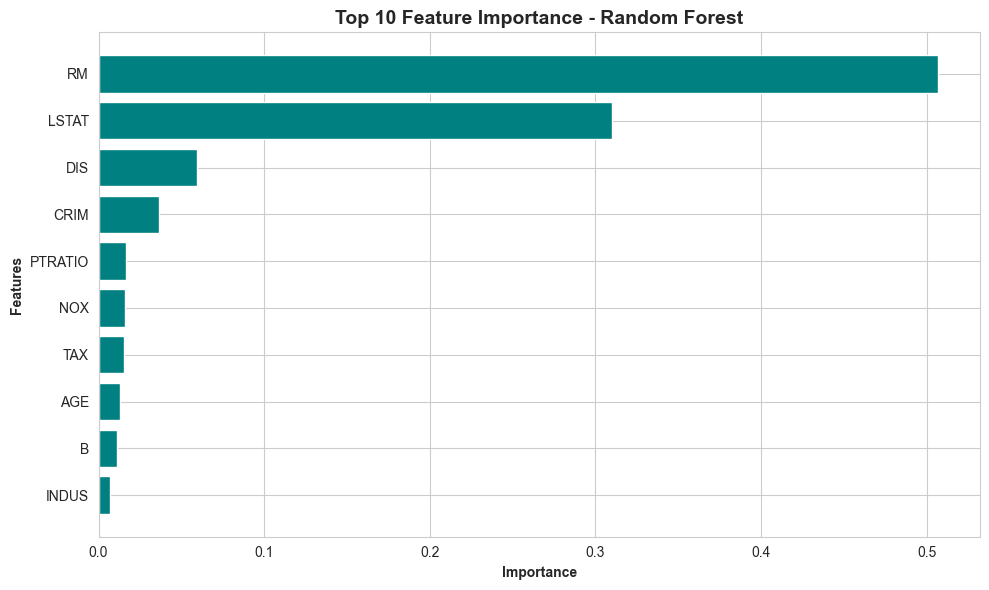


PROJECT SUMMARY
✓ Dataset: 4) house Prediction Data Set.csv
✓ Total Samples: 506
✓ Features: 13
✓ Models Trained: 3
✓ Best Model: Random Forest
✓ Best Test R² Score: 0.8942
✓ Best Test RMSE: $2.79k
✓ Project completed successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("="*70)
print("HOUSE PRICE PREDICTION - REGRESSION PROJECT")
print("="*70)

# STEP 1: LOAD DATA
print("\n[STEP 1] Loading Dataset...")
print("-"*70)

df = pd.read_csv('4) house Prediction Data Set.csv', header=None, delim_whitespace=True)
df.columns = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']


# Load data without headers
df = pd.read_csv('4) house Prediction Data Set.csv', header=None, delim_whitespace=True)

# Define column names based on Boston Housing Dataset structure
column_names = [ 'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE','DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

df.columns = column_names

print(f"✓ Dataset loaded successfully!")
print(f"  Shape: {df.shape}")
print(f"  Rows: {df.shape[0]} | Columns: {df.shape[1]}")

# STEP 2: EXPLORATORY DATA ANALYSIS
print("\n[STEP 2] Exploratory Data Analysis")
print("-"*70)

print("\n📊 First 5 rows:")
print(df.head())

print("\n📊 Dataset Information:")
print(df.info())

print("\n📊 Statistical Summary:")
print(df.describe())

print("\n📊 Missing Values:")
print(df.isnull().sum())

print("\n📊 Target Variable (MEDV - Median House Value):")
print(f"  Mean: ${df['MEDV'].mean():.2f}k")
print(f"  Median: ${df['MEDV'].median():.2f}k")
print(f"  Min: ${df['MEDV'].min():.2f}k")
print(f"  Max: ${df['MEDV'].max():.2f}k")

# Correlation Analysis
print("\n📊 Top 5 Features Correlated with House Price (MEDV):")
correlation = df.corr()['MEDV'].sort_values(ascending=False)
print(correlation.head(6))

# STEP 3: DATA VISUALIZATION
print("\n[STEP 3] Creating Visualizations...")
print("-"*70)

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Distribution of Target Variable
axes[0, 0].hist(df['MEDV'], bins=30, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Distribution of House Prices (MEDV)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Price ($1000s)')
axes[0, 0].set_ylabel('Frequency')

# 2. Correlation Heatmap (top features)
top_features = correlation.head(8).index
corr_matrix = df[top_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0, 1], 
            cbar_kws={'label': 'Correlation'})
axes[0, 1].set_title('Correlation Heatmap - Top Features', fontsize=14, fontweight='bold')

# 3. Scatter plot: RM vs MEDV
axes[1, 0].scatter(df['RM'], df['MEDV'], alpha=0.5, color='green')
axes[1, 0].set_title('Rooms (RM) vs House Price', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Average Number of Rooms')
axes[1, 0].set_ylabel('House Price ($1000s)')

# 4. Scatter plot: LSTAT vs MEDV
axes[1, 1].scatter(df['LSTAT'], df['MEDV'], alpha=0.5, color='red')
axes[1, 1].set_title('Lower Status % (LSTAT) vs House Price', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('% Lower Status Population')
axes[1, 1].set_ylabel('House Price ($1000s)')

plt.tight_layout()
plt.savefig('eda_visualizations.png', dpi=300, bbox_inches='tight')
print("✓ Visualizations saved as 'eda_visualizations.png'")
plt.show()

# STEP 4: PREPARE DATA FOR MODELING
print("\n[STEP 4] Preparing Data for Modeling")
print("-"*70)

# Separate features and target
X = df.drop('MEDV', axis=1)
y = df['MEDV']

print(f"✓ Features (X): {X.shape}")
print(f"✓ Target (y): {y.shape}")

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\n✓ Training set: {X_train.shape[0]} samples")
print(f"✓ Testing set: {X_test.shape[0]} samples")
print(f"✓ Split ratio: 80% train, 20% test")

# STEP 5: BUILD AND TRAIN MODELS
print("\n[STEP 5] Building and Training Models")
print("-"*70)

# Dictionary to store models and results
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42, max_depth=10),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
}

results = {}

for name, model in models.items():
    print(f"\n🔧 Training {name}...")
    
    # Train model
    model.fit(X_train, y_train)
    
    # Make predictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    
    # Calculate metrics
    train_mse = mean_squared_error(y_train, y_pred_train)
    test_mse = mean_squared_error(y_test, y_pred_test)
    train_rmse = np.sqrt(train_mse)
    test_rmse = np.sqrt(test_mse)
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    
    # Store results
    results[name] = {
        'model': model,
        'train_mse': train_mse,
        'test_mse': test_mse,
        'train_rmse': train_rmse,
        'test_rmse': test_rmse,
        'train_r2': train_r2,
        'test_r2': test_r2,
        'test_mae': test_mae,
        'y_pred': y_pred_test
    }
    
    print(f"   ✓ {name} trained successfully!")

# STEP 6: EVALUATE AND COMPARE MODELS
print("\n[STEP 6] Model Performance Evaluation")
print("="*70)

# Create comparison dataframe
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Train RMSE': [results[m]['train_rmse'] for m in results.keys()],
    'Test RMSE': [results[m]['test_rmse'] for m in results.keys()],
    'Train R²': [results[m]['train_r2'] for m in results.keys()],
    'Test R²': [results[m]['test_r2'] for m in results.keys()],
    'Test MAE': [results[m]['test_mae'] for m in results.keys()]
})

print("\n📊 MODEL COMPARISON TABLE:")
print("-"*70)
print(comparison_df.to_string(index=False))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test R²'].idxmax(), 'Model']
print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"   Test R² Score: {comparison_df.loc[comparison_df['Test R²'].idxmax(), 'Test R²']:.4f}")
print(f"   Test RMSE: {comparison_df.loc[comparison_df['Test R²'].idxmax(), 'Test RMSE']:.4f}")

# STEP 7: VISUALIZATION OF RESULTS
print("\n[STEP 7] Creating Performance Visualizations...")
print("-"*70)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Model Comparison - R² Score
model_names = list(results.keys())
train_r2_scores = [results[m]['train_r2'] for m in model_names]
test_r2_scores = [results[m]['test_r2'] for m in model_names]

x = np.arange(len(model_names))
width = 0.35

axes[0, 0].bar(x - width/2, train_r2_scores, width, label='Train R²', color='skyblue')
axes[0, 0].bar(x + width/2, test_r2_scores, width, label='Test R²', color='orange')
axes[0, 0].set_xlabel('Models', fontweight='bold')
axes[0, 0].set_ylabel('R² Score', fontweight='bold')
axes[0, 0].set_title('R² Score Comparison', fontsize=14, fontweight='bold')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(model_names, rotation=15)
axes[0, 0].legend()
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Model Comparison - RMSE
train_rmse_scores = [results[m]['train_rmse'] for m in model_names]
test_rmse_scores = [results[m]['test_rmse'] for m in model_names]

axes[0, 1].bar(x - width/2, train_rmse_scores, width, label='Train RMSE', color='lightgreen')
axes[0, 1].bar(x + width/2, test_rmse_scores, width, label='Test RMSE', color='salmon')
axes[0, 1].set_xlabel('Models', fontweight='bold')
axes[0, 1].set_ylabel('RMSE', fontweight='bold')
axes[0, 1].set_title('RMSE Comparison (Lower is Better)', fontsize=14, fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(model_names, rotation=15)
axes[0, 1].legend()
axes[0, 1].grid(axis='y', alpha=0.3)

# 3. Best Model - Actual vs Predicted
best_results = results[best_model_name]
axes[1, 0].scatter(y_test, best_results['y_pred'], alpha=0.5, color='blue')
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
                'r--', lw=2, label='Perfect Prediction')
axes[1, 0].set_xlabel('Actual Price ($1000s)', fontweight='bold')
axes[1, 0].set_ylabel('Predicted Price ($1000s)', fontweight='bold')
axes[1, 0].set_title(f'{best_model_name} - Actual vs Predicted', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Residual Plot for Best Model
residuals = y_test - best_results['y_pred']
axes[1, 1].scatter(best_results['y_pred'], residuals, alpha=0.5, color='purple')
axes[1, 1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1, 1].set_xlabel('Predicted Price ($1000s)', fontweight='bold')
axes[1, 1].set_ylabel('Residuals', fontweight='bold')
axes[1, 1].set_title(f'{best_model_name} - Residual Plot', fontsize=14, fontweight='bold')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('model_performance.png', dpi=300, bbox_inches='tight')
print("✓ Performance visualizations saved as 'model_performance.png'")
plt.show()

# STEP 8: FEATURE IMPORTANCE (for tree-based models)
print("\n[STEP 8] Feature Importance Analysis")
print("-"*70)

if best_model_name in ['Decision Tree', 'Random Forest']:
    feature_importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': best_results['model'].feature_importances_
    }).sort_values('Importance', ascending=False)
    
    print(f"\n📊 Top 10 Important Features ({best_model_name}):")
    print(feature_importance.head(10).to_string(index=False))
    
    # Plot feature importance
    plt.figure(figsize=(10, 6))
    plt.barh(feature_importance['Feature'].head(10), 
             feature_importance['Importance'].head(10), 
             color='teal')
    plt.xlabel('Importance', fontweight='bold')
    plt.ylabel('Features', fontweight='bold')
    plt.title(f'Top 10 Feature Importance - {best_model_name}', 
              fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
    print("\n✓ Feature importance plot saved as 'feature_importance.png'")
    plt.show()

# FINAL SUMMARY
print("\n" + "="*70)
print("PROJECT SUMMARY")
print("="*70)
print(f"✓ Dataset: 4) house Prediction Data Set.csv")
print(f"✓ Total Samples: {df.shape[0]}")
print(f"✓ Features: {df.shape[1] - 1}")
print(f"✓ Models Trained: {len(models)}")
print(f"✓ Best Model: {best_model_name}")
print(f"✓ Best Test R² Score: {results[best_model_name]['test_r2']:.4f}")
print(f"✓ Best Test RMSE: ${results[best_model_name]['test_rmse']:.2f}k")
print("="*70)
print("✓ Project completed successfully!")
print("="*70)